

```
# This is formatted as code
```

# Task 5 — Robustness of PDE-based heat-source reconstruction

**Research objective.** Test how inverse reconstruction depends on observation noise, the number of temperature sensors, regularization strength, and optimization algorithm. Uses **Task 3** data without rebuilding the original PDE forward experiment.

Task 3 gives $d_\mathrm{clean}=A\theta_\mathrm{true}$, with $A\in\mathbb R^{48\times3}$. Noise is introduced as $d=d_\mathrm{clean}+\varepsilon$.

For $m$ observations, we minimize

$$J_\lambda(\theta)=\frac{1}{2m}\lVert A\theta-d\rVert_2^2+\frac\lambda2\lVert\theta\rVert_2^2.$$

**Important:** This simple 3-parameter problem is relatively well-conditioned. It may show that weak/no regularization is better for coefficient accuracy; stronger inverse ill-conditioning is reserved for a later extension.

In [13]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.sparse.linalg import cg

p = Path('phase3_observation_data.npz')
if not p.exists():
    from google.colab import files
    print('Upload phase3_observation_data.npz')
    files.upload()
data = np.load('phase3_observation_data.npz')
A, d_clean, d_noisy = data['A'], data['d_clean'], data['d_noisy']
theta_true, basis, f_true = data['theta_true'], data['basis'], data['source_true']
print('A shape:', A.shape, 'true coefficients:', theta_true)
assert A.shape == (48, 3) and np.linalg.matrix_rank(A) == 3
assert np.allclose(d_clean, A @ theta_true, atol=1e-12)

A shape: (48, 3) true coefficients: [1.2  0.85 1.05]


## 1. Numerical reconstruction routine

Use singular value decomposition instead of explicitly forming $A^TA$ for the ridge estimator. For $A=U\Sigma V^T$, the solution is

$$\hat\theta_\lambda=V\operatorname{diag}\!\left(\frac{\sigma_i}{\sigma_i^2+m\lambda}\right)U^Td.$$

For $\lambda=0$, this is the full-column-rank least-squares solution.

In [14]:
def reconstruct(A, observed, lam=0.0):
    U, s, Vt = np.linalg.svd(A, full_matrices=False)
    return Vt.T @ ((s / (s*s + len(observed)*lam)) * (U.T @ observed))

def coefficient_error(theta):
    return np.linalg.norm(theta-theta_true)/np.linalg.norm(theta_true)

def source_error(theta):
    field = np.einsum('p,pij->ij', theta, basis)
    return np.linalg.norm(field-f_true)/np.linalg.norm(f_true)

for lam in [0.0,1e-7]:
    th = reconstruct(A,d_noisy,lam)
    print('lambda:',lam,'theta:',np.round(th,6),
          'coefficient error:',round(100*coefficient_error(th),3),'%',
          'source error:',round(100*source_error(th),3),'%')

lambda: 0.0 theta: [1.203937 0.85309  1.062738] coefficient error: 0.757 % source error: 0.688 %
lambda: 1e-07 theta: [1.202577 0.852704 1.060681] coefficient error: 0.626 % source error: 0.568 %


## 2. Repeated trials under increasing measurement noise

At each level $\eta\in\{0,1,3,5,10\}\%$, generate 150 independent noise realizations with standard deviation $\eta\max_k|d_k^{\mathrm{clean}}|$. Report *mean* coefficient and source error. A fixed random seed ensures reproducibility. All noise percentages refer to the **peak clean temperature observation**, not to every measurement.

In [15]:
rng=np.random.default_rng(20261017)
repetitions=150
noise_levels=np.array([0,.01,.03,.05,.10])
scale=np.max(np.abs(d_clean))
noise_scores=np.empty((len(noise_levels),repetitions,2))
noise_fields=np.empty_like(noise_scores)
for i,level in enumerate(noise_levels):
    for rep in range(repetitions):
        y=d_clean+rng.normal(0,level*scale,size=len(d_clean))
        for k,lam in enumerate([0.,1e-7]):
            th=reconstruct(A,y,lam)
            noise_scores[i,rep,k]=coefficient_error(th)
            noise_fields[i,rep,k]=source_error(th)
for level,values in zip(noise_levels,noise_scores):
    print(f'Noise {100*level:>4.0f}%: mean coefficient errors OLS={100*values[:,0].mean():.3f}%, ridge={100*values[:,1].mean():.3f}%')

Noise    0%: mean coefficient errors OLS=0.000%, ridge=0.137%
Noise    1%: mean coefficient errors OLS=0.657%, ridge=0.669%
Noise    3%: mean coefficient errors OLS=1.923%, ridge=1.921%
Noise    5%: mean coefficient errors OLS=3.463%, ridge=3.469%
Noise   10%: mean coefficient errors OLS=6.816%, ridge=6.806%


## 3. Fewer spatial sensors

The 48 rows are organized as three consecutive blocks of 16 sensors, one block per observation time. We construct **nested spatial sensor subsets** of sizes 3, 4, 6, 8, 12, and 16 and use the same spatial locations at each of the three times. All cases have at least as many measurements as source coefficients; rank and condition number are checked.

In [16]:
n_sensors=np.array([3,4,6,8,12,16])
perm=np.random.default_rng(42).permutation(16)
sensor_scores=np.empty((len(n_sensors),repetitions,2))
condition_numbers=[]
for i,ns in enumerate(n_sensors):
    indices=np.concatenate([perm[:ns]+16*t for t in range(3)])
    a=A[indices,:]; clean=d_clean[indices]
    condition_numbers.append(np.linalg.cond(a))
    assert np.linalg.matrix_rank(a)==3
    for rep in range(repetitions):
        y=clean+rng.normal(0,.05*scale,size=len(clean))
        for k,lam in enumerate([0.,1e-7]):
            sensor_scores[i,rep,k]=coefficient_error(reconstruct(a,y,lam))
for ns,c,vals in zip(n_sensors,condition_numbers,sensor_scores):
    print(f'{ns:2d} sensors: cond(A)={c:.2f}, mean error OLS={100*vals[:,0].mean():.2f}%, ridge={100*vals[:,1].mean():.2f}%')

 3 sensors: cond(A)=120.68, mean error OLS=322.68%, ridge=60.16%
 4 sensors: cond(A)=27.13, mean error OLS=65.23%, ridge=52.47%
 6 sensors: cond(A)=35.83, mean error OLS=57.83%, ridge=40.78%
 8 sensors: cond(A)=2.00, mean error OLS=4.45%, ridge=4.44%
12 sensors: cond(A)=1.38, mean error OLS=3.65%, ridge=3.65%
16 sensors: cond(A)=1.81, mean error OLS=3.03%, ridge=3.03%


## 4. Regularization sweep

For one fixed 5% noise realization, compare $\lambda=0$ with a logarithmic grid of positive regularization strengths. Selecting the parameter using the true coefficients is an **oracle diagnostic**, not a deployable parameter-selection strategy. In real applications we would use validation, discrepancy principles, or other data-based criteria.

In [17]:
noise5=rng.normal(0,.05*scale,size=A.shape[0]); y5=d_clean+noise5
lambdas=np.r_[0.,np.logspace(-9,-3,35)]
regularization_error=np.array([coefficient_error(reconstruct(A,y5,l)) for l in lambdas])
print('Unregularized error:',100*regularization_error[0],'%')
print('Best error in this one sweep:',100*regularization_error.min(),'%, at lambda=',lambdas[regularization_error.argmin()])

Unregularized error: 0.6195959014462795 %
Best error in this one sweep: 0.5201832628705433 %, at lambda= 2.9552092352028877e-07


## 5. Algorithm verification

For a fixed $\lambda=10^{-7}$ and the **original Task 3 noisy dataset**, compare BFGS, L-BFGS-B (unconstrained), conjugate gradient on the positive-definite normal equations, and a direct solution. Their optimized coefficient vectors should agree, even if iteration counts differ.

In [18]:
lam=1e-7
M=A.T@A+len(d_noisy)*lam*np.eye(3)
rhs=A.T@d_noisy
reference=np.linalg.solve(M,rhs)
def objective(th):
    r=A@th-d_noisy
    return np.dot(r,r)/(2*len(d_noisy))+lam*np.dot(th,th)/2
def gradient(th):
    return A.T@(A@th-d_noisy)/len(d_noisy)+lam*th
for method in ['BFGS','L-BFGS-B']:
    options={'gtol':1e-11,'maxiter':10000}
    if method=='L-BFGS-B': options['ftol']=1e-15
    res=minimize(objective,np.zeros(3),jac=gradient,method=method,options=options)
    print(method, 'iters:',res.nit, 'objective:',objective(res.x),
          'gradient norm:',np.linalg.norm(gradient(res.x)),
          'distance from direct:',np.linalg.norm(res.x-reference),
          'message:',res.message)
sol,info=cg(M,rhs,rtol=1e-12,atol=0)
print('CG info:',info, 'distance from direct:',np.linalg.norm(sol-reference))

BFGS iters: 28 objective: 2.364062734069291e-07 gradient norm: 1.1569123444836505e-12 distance from direct: 1.7184285224222183e-08 message: Optimization terminated successfully.
L-BFGS-B iters: 9 objective: 2.3640627340691946e-07 gradient norm: 1.2235339398589525e-13 distance from direct: 1.026755380399941e-09 message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
CG info: 0 distance from direct: 3.1401849173675503e-16


## 6. Visual summary

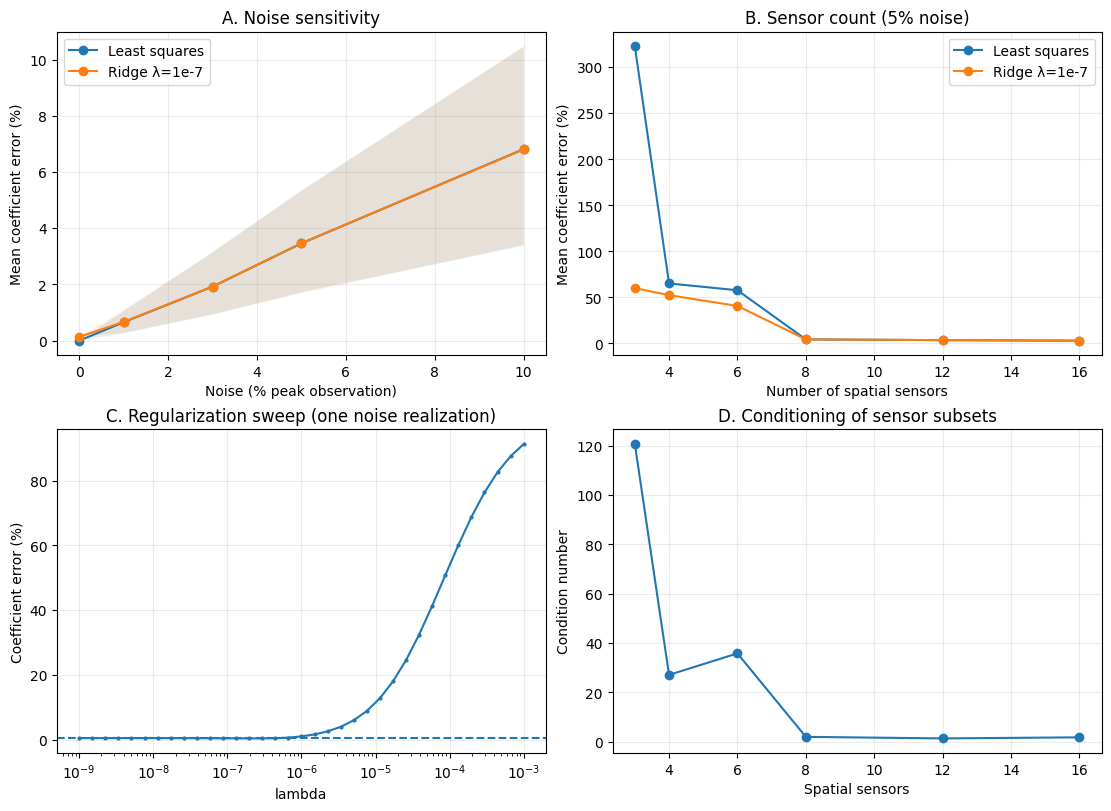

In [19]:
fig,axs=plt.subplots(2,2,figsize=(11,8),layout='constrained')
ax=axs[0,0]
for k,label in enumerate(['Least squares','Ridge λ=1e-7']):
    ax.plot(noise_levels*100,100*noise_scores[:,:,k].mean(axis=1),'-o',label=label)
    ax.fill_between(noise_levels*100,100*np.percentile(noise_scores[:,:,k],10,axis=1),100*np.percentile(noise_scores[:,:,k],90,axis=1),alpha=.12)
ax.set(title='A. Noise sensitivity',xlabel='Noise (% peak observation)',ylabel='Mean coefficient error (%)');ax.legend();ax.grid(alpha=.25)
ax=axs[0,1]
for k,label in enumerate(['Least squares','Ridge λ=1e-7']):ax.plot(n_sensors,100*sensor_scores[:,:,k].mean(axis=1),'-o',label=label)
ax.set(title='B. Sensor count (5% noise)',xlabel='Number of spatial sensors',ylabel='Mean coefficient error (%)');ax.legend();ax.grid(alpha=.25)
ax=axs[1,0];ax.semilogx(lambdas[1:],100*regularization_error[1:],'-o',markersize=2);ax.axhline(100*regularization_error[0],linestyle='--')
ax.set(title='C. Regularization sweep (one noise realization)',xlabel='lambda',ylabel='Coefficient error (%)');ax.grid(alpha=.25)
ax=axs[1,1];ax.plot(n_sensors,condition_numbers,'-o');ax.set(title='D. Conditioning of sensor subsets',xlabel='Spatial sensors',ylabel='Condition number');ax.grid(alpha=.25)
fig.savefig('phase5_robustness_experiments.png',dpi=175)
plt.show()

In [23]:

# Task 5: Safely export numerical experiment results

import numpy as np

variables_to_save = [
    "noise_levels",
    "noise_scores",
    "noise_field",
    "n_sensors",
    "sensor_scores",
    "condition_numbers",
    "lambdas",
    "regularization_error",
    "theta_true",
    "A",
    "d_clean",
    "d_noisy"
]

available = {
    name: np.asarray(globals()[name])
    for name in variables_to_save
    if name in globals()
}

missing = [
    name for name in variables_to_save
    if name not in globals()
]

np.savez_compressed(
    "phase5_experiment_results.npz",
    **available
)

print("Saved variables:", list(available.keys()))
print("Missing variables:", missing)
print("Task 5 numerical results saved successfully!")


Saved variables: ['noise_levels', 'noise_scores', 'n_sensors', 'sensor_scores', 'condition_numbers', 'lambdas', 'regularization_error', 'theta_true', 'A', 'd_clean', 'd_noisy']
Missing variables: ['noise_field']
Task 5 numerical results saved successfully!


## 7. Interpretation and limitations

- Check how noise changes reconstruction accuracy and whether the reported mean is stable across random samples.
- Examine the number **and placement** of sensors; this experiment changes both through a fixed random subset ordering.
- Distinguish minimizing the data-fitting objective from minimizing the unknown source error. The true source is available here only because the experiment is synthetic.
- Compare algorithms **for the same objective and data**, avoiding the false implication that an optimizer changes the model's attainable optimum.
- This low-dimensional, well-conditioned inverse problem is a baseline. A more demanding extension will involve many more basis functions, stronger correlation between them, or sparser observations.

**Scientific caution:** a small error on synthetic data does not imply general-purpose source identification for arbitrary spatial sources.